# Chapitre 6 - Cours 2 : Évaluer et optimiser la recherche

Le cours 1 a présenté les deux familles de retrievers. Ce notebook apprend à les **mesurer**
puis à les **améliorer**. Il couvre la fin de la section *Retrieval Algorithms* (évaluation,
*Combining retrieval algorithms*) et la section *Retrieval Optimization* :

1. les métriques de recherche : précision@k, rappel@k, MRR, MAP, NDCG ;
2. l'évaluation de nos retrievers sur les 42 questions annotées ;
3. la recherche hybride : fusion RRF, fusion linéaire, cascade ;
4. les stratégies de découpage et leur effet mesuré ;
5. le reranking par cross-encoder et par LLM ;
6. la réécriture de requête dans une conversation ;
7. la recherche contextuelle ;
8. les critères de choix d'une solution de recherche.

In [1]:
import os

os.environ["HF_HUB_OFFLINE"] = "1"          # modèles déjà en cache : aucun appel réseau
os.environ["HF_HUB_VERBOSITY"] = "error"
import logging
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from transformers import AutoTokenizer

from aie import llm
from aie import ch06_rag_agents as c6
from aie.diagrams import Diagram
from aie.plotting import (AMBER, COLORS, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET,
                          annotate_bars, finish, set_style, subtitle)

set_style()
warnings.filterwarnings("ignore")
logging.getLogger("huggingface_hub").setLevel(logging.ERROR)
llm.seed_everything(0)
pd.set_option("display.max_colwidth", 110)
P = c6.passages()
TEXTS, IDS = [p.text for p in P], [p.pid for p in P]
TXT = dict(zip(IDS, TEXTS))
Q = c6.QUESTIONS
qwen_tok = AutoTokenizer.from_pretrained(llm.SMALL)
ntok = lambda t: len(qwen_tok(t)["input_ids"])  # noqa: E731

## 1. Mesurer la qualité d'un retriever (section *Comparing retrieval algorithms*)

On évalue un retriever sur un **jeu d'évaluation** : des requêtes de test et, pour chacune,
l'annotation des documents pertinents (par des humains ou un juge IA). Notons $R_k$ les $k$
premiers documents renvoyés et $\mathcal P$ l'ensemble des documents pertinents.

- **Précision@k** (*context precision*) : quelle part des documents renvoyés est pertinente ?
  $\;P@k = |R_k \cap \mathcal P| / k$.
- **Rappel@k** (*context recall*) : quelle part des documents pertinents a été retrouvée ?
  $\;R@k = |R_k \cap \mathcal P| / |\mathcal P|$. Il exige d'avoir annoté **tous** les
  documents de la base pour chaque requête, d'où le fait que certains outils de production ne
  calculent que la précision (un juge IA peut noter les seuls documents renvoyés).
- **MRR** (*mean reciprocal rank*) : moyenne de $1/\text{rang}$ du premier document pertinent.
  Il récompense le fait d'avoir **un** bon document **tôt**.
- **MAP** : moyenne, sur les requêtes, de la précision moyenne aux rangs des documents
  pertinents.
- **NDCG@k** : gain cumulé actualisé, qui accepte des **notes graduées** $g_i$ (ici 2 = très
  pertinent, 1 = pertinent) et pénalise logarithmiquement les rangs tardifs :
  $$\mathrm{DCG@k} = \sum_{i=1}^{k} \frac{g_i}{\log_2(i+1)}, \qquad
    \mathrm{NDCG@k} = \frac{\mathrm{DCG@k}}{\mathrm{IDCG@k}} \in [0, 1],$$
  où IDCG est le DCG du classement idéal.

Exemple : trois documents pertinents (a noté 2, b et c notés 1) et deux classements qui
ont **la même précision@5** mais pas le même ordre.

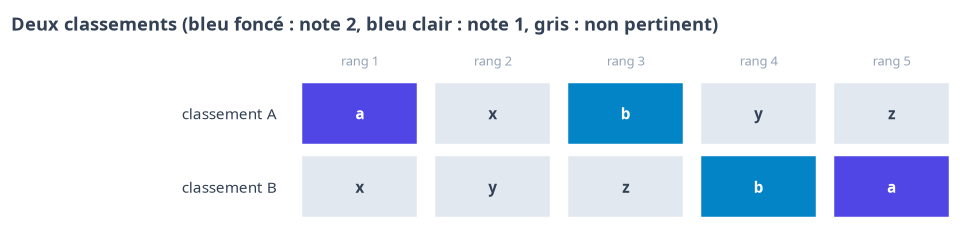

,P@5,R@5,RR,AP,NDCG@5
classement A,0.4,0.667,1.00,0.556,0.798
classement B,0.4,0.667,0.25,0.217,0.385


In [2]:
rel = {"a": 2, "b": 1, "c": 1}
classements = {"classement A": ["a", "x", "b", "y", "z"], "classement B": ["x", "y", "z", "b", "a"]}
fig, ax = plt.subplots(figsize=(9, 2.3))
couleur = {2: INDIGO, 1: SKY, 0: "#E2E8F0"}
for row, (nom, r) in enumerate(classements.items()):
    for i, dname in enumerate(r):
        g = rel.get(dname, 0)
        ax.add_patch(plt.Rectangle((i, -row - 0.4), 0.85, 0.8, color=couleur[g]))
        ax.text(i + 0.425, -row, dname, ha="center", va="center", color="white" if g else SLATE, fontweight="bold")
    ax.text(-0.2, -row, nom, ha="right", va="center", fontsize=10)
for i in range(5):
    ax.text(i + 0.425, 0.65, f"rang {i + 1}", ha="center", fontsize=8.5, color=GRAY)
ax.set_xlim(-2.2, 5); ax.set_ylim(-1.6, 1.0); ax.axis("off")
ax.set_title("Deux classements (bleu foncé : note 2, bleu clair : note 1, gris : non pertinent)")
plt.tight_layout(); plt.show()
pd.DataFrame({nom: {"P@5": c6.precision_at_k(r, rel, 5), "R@5": c6.recall_at_k(r, rel, 5),
                    "RR": c6.reciprocal_rank(r, rel), "AP": c6.average_precision(r, rel),
                    "NDCG@5": c6.ndcg_at_k(r, rel, 5)} for nom, r in classements.items()}).T.round(3)

La précision et le rappel ignorent l'ordre ; RR, AP et NDCG le prennent en compte. Pour un
RAG, l'ordre importe moins qu'en recherche Web (le livre le souligne dans *Reranking*) : un
document inclus dans le contexte est lu quelle que soit sa position, même si les modèles
exploitent mieux le début et la fin du contexte. Le rappel@k, lui, est crucial : un passage
absent du contexte est perdu.

> **À retenir.** Précision@k et rappel@k mesurent **quoi** est renvoyé ; MRR, MAP et NDCG
> mesurent aussi **dans quel ordre**. Le rappel exige une annotation exhaustive ; la
> précision peut être jugée par un modèle sur les seuls documents renvoyés.

## 2. Évaluer nos retrievers (section *Comparing retrieval algorithms*)

Appliquons ces métriques aux retrievers du cours 1 sur les 42 questions. Pour chaque
question, on garde les 20 premiers passages.

In [3]:
bm25 = c6.TermRetriever(TEXTS, IDS)
retrievers = {"TF-IDF": c6.TermRetriever(TEXTS, IDS, "tfidf"), "BM25": bm25,
              "dense EN": c6.DenseRetriever(TEXTS, IDS, llm.EMBED), "dense multi": c6.DenseRetriever(TEXTS, IDS, llm.EMBED_MULTI)}
dense = retrievers["dense multi"]
runs = {n: {q["qid"]: r.search(q["question"], 20) for q in Q} for n, r in retrievers.items()}
pd.DataFrame({n: c6.evaluate(r, k=5) for n, r in runs.items()}).T.round(3)

,P@5,R@5,Hit@5,MRR,NDCG@5
TF-IDF,0.195,0.905,0.929,0.764,0.785
BM25,0.195,0.905,0.929,0.784,0.803
dense EN,0.176,0.821,0.833,0.673,0.694
dense multi,0.210,0.964,0.976,0.836,0.864


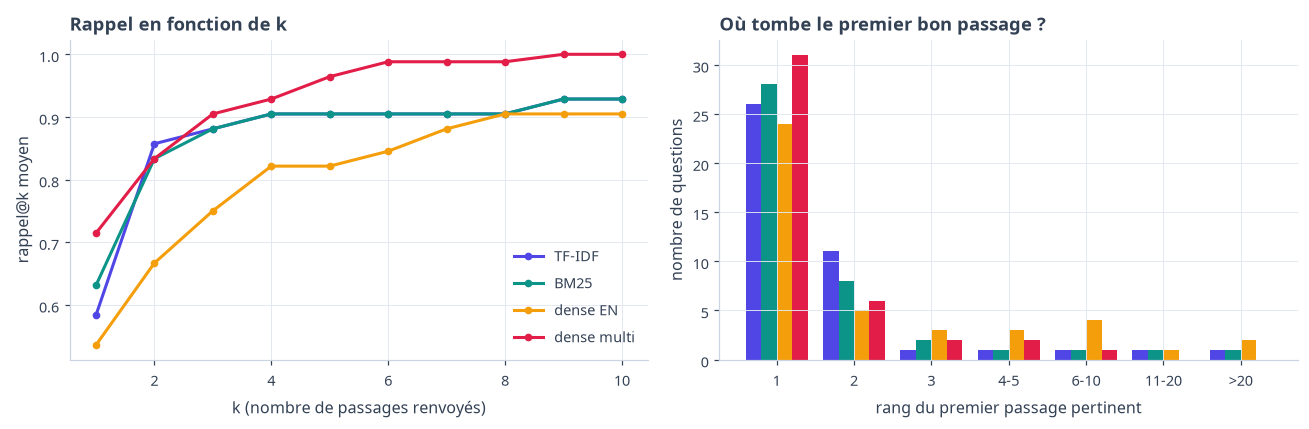

In [4]:
ks = np.arange(1, 11)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
cols = dict(zip(runs, [INDIGO, TEAL, AMBER, ROSE]))
for n, r in runs.items():
    axes[0].plot(ks, [np.mean([c6.recall_at_k(r[q["qid"]], q["relevant"], k) for q in Q]) for k in ks],
                 marker="o", ms=4, color=cols[n], label=n)
axes[0].set_xlabel("k (nombre de passages renvoyés)"); axes[0].set_ylabel("rappel@k moyen")
axes[0].set_title("Rappel en fonction de k"); axes[0].legend()
rangs = {n: [next((i + 1 for i, d in enumerate(r[q["qid"]]) if d in q["relevant"]), 21) for q in Q] for n, r in runs.items()}
bins = [1, 2, 3, 4, 6, 11, 21, 22]
lab = ["1", "2", "3", "4-5", "6-10", "11-20", ">20"]
width = 0.2
for j, (n, rg) in enumerate(rangs.items()):
    h = np.histogram(rg, bins=bins)[0]
    axes[1].bar(np.arange(len(lab)) + (j - 1.5) * width, h, width, color=cols[n], label=n)
axes[1].set_xticks(range(len(lab))); axes[1].set_xticklabels(lab)
axes[1].set_xlabel("rang du premier passage pertinent"); axes[1].set_ylabel("nombre de questions")
axes[1].set_title("Où tombe le premier bon passage ?")
finish(fig); plt.show()

Avec $k = 5$, le modèle multilingue retrouve le bon passage pour presque toutes les questions,
BM25 pour un peu moins ; la précision@5 plafonne mécaniquement vers 0,2 car la plupart des
questions n'ont qu'un passage pertinent (au mieux 1/5). Le choix de $k$ est un compromis :
plus de passages augmente le rappel mais aussi le nombre de tokens envoyés au générateur (et
le bruit qu'il doit ignorer).

> **À retenir.** Toujours tracer le **rappel@k en fonction de k** : il dit combien de passages
> il faut envoyer au générateur pour ne pas perdre l'information.

## 3. Recherche hybride (section *Combining retrieval algorithms*)

Combiner recherche par termes et par embeddings s'appelle la **recherche hybride**. Deux
manières :

- **en cascade** : un retriever bon marché (BM25) présélectionne des candidats, un mécanisme
  plus précis et plus cher les reclasse (c'est déjà du *reranking*) ;
- **en parallèle** : plusieurs retrievers produisent chacun un classement, qu'on **fusionne**.

La **fusion par rang réciproque** (RRF, Cormack et al., 2009) n'utilise que les rangs :
$$\mathrm{RRF}(D) = \sum_{i=1}^{n} \frac{1}{k + r_i(D)},$$
où $r_i(D)$ est le rang de $D$ pour le retriever $i$ et $k$ une constante (typiquement 60) qui
évite la division par zéro et atténue l'écart entre les premiers rangs. Avantage décisif : pas
besoin de rendre comparables des scores BM25 (non bornés) et des cosinus (dans $[-1, 1]$).

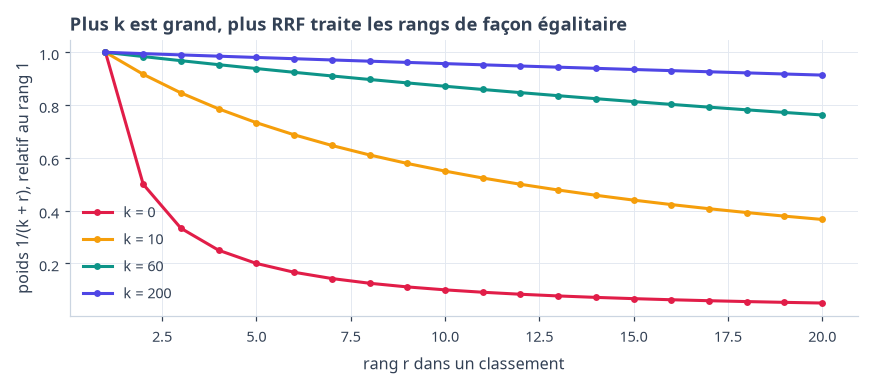

In [5]:
r_ = np.arange(1, 21)
fig, ax = plt.subplots(figsize=(8, 3.6))
for k_, col in [(0, ROSE), (10, AMBER), (60, TEAL), (200, INDIGO)]:
    w = 1 / (k_ + r_)
    ax.plot(r_, w / w[0], marker="o", ms=3.5, color=col, label=f"k = {k_}")
ax.set_xlabel("rang r dans un classement"); ax.set_ylabel("poids 1/(k + r), relatif au rang 1")
ax.set_title("Plus k est grand, plus RRF traite les rangs de façon égalitaire")
ax.legend(); plt.tight_layout(); plt.show()

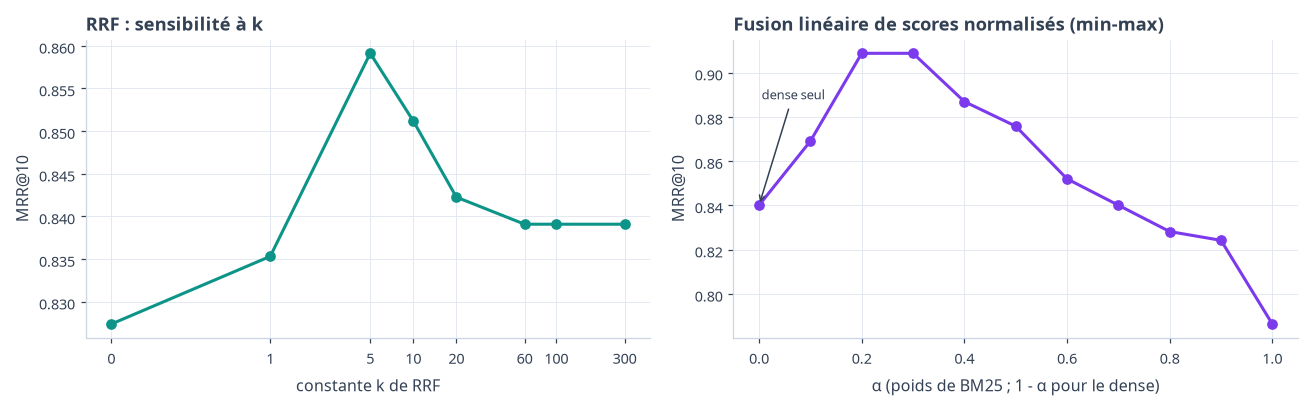

In [6]:
def hybride_rrf(k_=60, weights=None, depth=20):
    return {q["qid"]: [d for d, _ in c6.rrf([runs["BM25"][q["qid"]][:depth], runs["dense multi"][q["qid"]][:depth]], k_, weights)]
            for q in Q}

def hybride_lineaire(alpha):
    out = {}
    for q in Q:
        s = alpha * c6.minmax(bm25.scores(q["question"])) + (1 - alpha) * c6.minmax(dense.scores(q["question"]))
        out[q["qid"]] = c6.rank(s, IDS, 20)
    return out

def cascade(n_cand=10):
    out = {}
    for q in Q:
        cand = runs["BM25"][q["qid"]][:n_cand]
        s = dense.scores(q["question"])
        out[q["qid"]] = sorted(cand, key=lambda d_: -s[IDS.index(d_)])
    return out

ks_rrf = [0, 1, 5, 10, 20, 60, 100, 300]
alphas = np.linspace(0, 1, 11)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].plot(ks_rrf, [c6.evaluate(hybride_rrf(k_), k=10)["MRR"] for k_ in ks_rrf], marker="o", color=TEAL)
axes[0].set_xscale("symlog", linthresh=1); axes[0].set_xticks(ks_rrf); axes[0].set_xticklabels(ks_rrf)
axes[0].set_xlabel("constante k de RRF"); axes[0].set_ylabel("MRR@10"); axes[0].set_title("RRF : sensibilité à k")
axes[1].plot(alphas, [c6.evaluate(hybride_lineaire(a), k=10)["MRR"] for a in alphas], marker="o", color=VIOLET)
axes[1].set_xlabel("α (poids de BM25 ; 1 - α pour le dense)"); axes[1].set_ylabel("MRR@10")
axes[1].set_title("Fusion linéaire de scores normalisés (min-max)")
for ax_, txt in [(axes[1], "dense seul"), ]:
    ax_.annotate(txt, (0, c6.evaluate(hybride_lineaire(0), k=10)["MRR"]), xytext=(0.05, 0.8), textcoords="axes fraction", fontsize=8.5,
                 arrowprops=dict(arrowstyle="->", color=SLATE))
finish(fig); plt.show()

In [7]:
variantes = {"BM25": runs["BM25"], "dense multi": runs["dense multi"], "RRF (k=60)": hybride_rrf(60),
             "linéaire (α=0,3)": hybride_lineaire(0.3), "cascade BM25 top-10 -> dense": cascade(10)}
tab = pd.DataFrame({n: c6.evaluate(r, k=5) for n, r in variantes.items()}).T
par_type = pd.DataFrame({n: c6.per_question(r, k=10).groupby("type")["RR"].mean() for n, r in variantes.items()}).T
pd.concat([tab[["R@5", "MRR", "NDCG@5"]], par_type.add_prefix("MRR ")], axis=1).round(3)

,R@5,MRR,NDCG@5,MRR ambigu,MRR lexical,MRR semantique
BM25,0.905,0.784,0.803,0.833,0.947,0.626
dense multi,0.964,0.836,0.864,0.833,0.870,0.812
RRF (k=60),0.929,0.832,0.841,1.000,0.947,0.712
"linéaire (α=0,3)",0.964,0.905,0.912,0.833,1.000,0.833
cascade BM25 top-10 -> dense,0.929,0.822,0.840,0.833,0.886,0.760


Lisons ce tableau avec honnêteté. RRF obtient le meilleur score sur les questions ambiguës et
lexicales, mais perd sur les questions sémantiques une partie de l'avance du dense : au total,
il fait jeu égal avec le dense, nettement mieux que BM25. La fusion **linéaire** avec
$\alpha = 0{,}3$ obtient le meilleur score global... mais $\alpha$ a été choisi **sur les
mêmes 42 questions** qui servent à l'évaluer : ce score est optimiste (sur-apprentissage du
réglage), et la courbe montre qu'un mauvais $\alpha$ coûte cher. RRF, lui, n'a rien à régler
(la courbe en $k$ est plate autour de 60) et n'a pas besoin de rendre les scores comparables.
La cascade est limitée par le rappel du premier étage : un passage que BM25 ne remonte pas dans
son top-10 ne peut pas être sauvé. Pour régler $\alpha$ proprement, il faudrait un jeu de
validation distinct du jeu de test (voir l'exercice 6.5).

> **À retenir.** **RRF** fusionne des classements sans calibrer les scores : $\sum_i 1/(k + r_i)$,
> avec $k \approx 60$. La recherche hybride combine la précision lexicale de BM25 et la
> souplesse sémantique des embeddings.